In [1]:
# suppressMessages(library(ArchR))
suppressMessages(library(Seurat))
suppressMessages(library(dplyr))
suppressMessages(library(igraph))
suppressMessages(library(ggraph))
suppressMessages(library(harmony))
library(igraph) 
library(qs) 
library(ggsci)

suppressMessages(library(reticulate))
RETICULATE_PYTHON <- "/home/chaiqw/project/betz_snRNA_snATAC/.venv/bin/python"
use_virtualenv("/home/chaiqw/project/betz_snRNA_snATAC/.venv")

plan("multicore", workers = 64)
options(future.globals.maxSize = 100000 * 1024^5)



qs 0.27.3. Announcement: https://github.com/qsbase/qs/issues/103



In [ ]:
### snRNA-seq L5-ET
rna = qread('/mnt/90-connectome/Personal/CQW/motor_snRNA_new/from_zzy_transfer/snRNA-data/keep3Animal_kepler_Anot_Betz.qs')
sub_rna = subset(rna, subclass == 'L5-ET(PT)' )

### Stereo-seq manu Betz cells
betz_obj = readRDS('/mnt/90-connectome/Personal/CQW/motor_snRNA_new/article/fig5/new_betz/seurat_filt4-20251106-new.rds')
sub_betz_obj = subset(betz_obj, betz_obj$source == 'manu_betz')

### Lein's L5-ET
var_Lein = qread('/mnt/90-connectome/Personal/CQW/motor_snRNA_new/article/fig5/new_betz/M1_L5_Lein_seuObj.qs')
cluster_id_selecet = c('Exc L5 FEZF2 LOC114676463 N=242','Exc L5 FEZF2 LOC106993015 N=241')
var_Lein_sub = subset(var_Lein, cluster_label %in% cluster_id_selecet)

In [ ]:
sub_rna$source = 'snRNA'
sub_betz_obj$source = 'stRNA'
sub_betz_obj$celltype = 'Betz cell'
var_Lein_sub$source = 'Lein_M1'
var_Lein_sub$celltype = var_Lein$Betz.annot

Normalizing layer: counts

Finding variable features for layer counts

Centering and scaling data matrix

Warning message:
“Different features in new layer data than already exists for scale.data”
Warning message:
“Number of dimensions changing from 50 to 20”
Computing nearest neighbor graph

Computing SNN

Warning message:
“UNRELIABLE VALUE: One of the ‘future.apply’ iterations (‘future_lapply-1’) unexpectedly generated random numbers without declaring so. There is a risk that those random numbers are not statistically sound and the overall results might be invalid. To fix this, specify 'future.seed=TRUE'. This ensures that proper, parallel-safe random numbers are produced via a parallel RNG method. To disable this check, use 'future.seed = NULL', or set option 'future.rng.onMisuse' to "ignore".”
Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.m

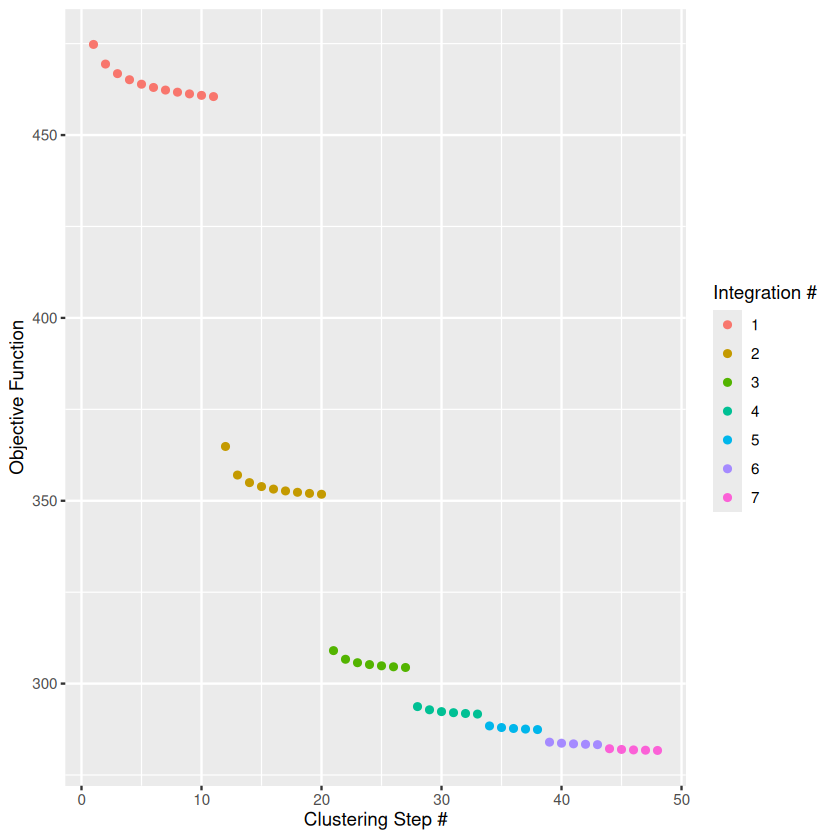

In [6]:
M1_data_sub_1 = JoinLayers(sub_rna)
M1_data_sub_1 <- M1_data_sub_1 %>% 
    NormalizeData(normalization.method = "LogNormalize") %>% 
    FindVariableFeatures( nfeatures = 5000) %>% 
    ScaleData() %>% 
    # SCTransform(variable.features.n = 2000) %>% 
    RunPCA(npcs=20,verbose = FALSE) 

M1_data_sub_2 <- M1_data_sub_1 %>% 
    FindNeighbors(dims = 1:5) %>%
    FindClusters(verbose = FALSE, resolution = 0.5, random.seed = 1234) %>%
    RunUMAP(dims = 1:5, seed.use = 1234)

M1_data_sub_3 = RunHarmony(
    M1_data_sub_2, group.by.vars=c("Animal"), plot_convergence=T,
    reduction.save = "harmony", dims.use=1:5,
    theta=2)

M1_data_sub_4 <- M1_data_sub_3 %>%
    FindNeighbors(reduction="harmony", dims = 1:5,k.param = 100) %>%
    FindClusters(verbose = FALSE,resolution = 0.4, random.seed = 666) %>%
    RunUMAP(reduction="harmony", dims = 1:5,min.dist = 0.2)

In [ ]:
# saveRDS(M1_data_sub_4, 'M1_data_sub_4.rds')

In [ ]:
M1_data_sub_1 = JoinLayers(sub_rna)

sub_downsampled_2$celltype_new <- as.character(sub_downsampled_2$celltype)
sub_downsampled_2$celltype_new[sub_downsampled_2$celltype_new %in% c("L5-ET(PT).02(Betz-Like)", "L5-ET(PT).00")] <- "Betz Like"
sub_downsampled_2$celltype_new <- as.factor(sub_downsampled_2$celltype_new)

M1_data_sub_1 <- M1_data_sub_1 %>% 
    NormalizeData(normalization.method = "LogNormalize") %>% 
    FindVariableFeatures( nfeatures = 5000) %>% 
    ScaleData() %>% 
    # SCTransform(variable.features.n = 2000) %>% 
    RunPCA(npcs=20,verbose = FALSE) 

M1_data_sub_2 <- M1_data_sub_1 %>% 
    FindNeighbors(dims = 1:5) %>%
    FindClusters(verbose = FALSE, resolution = 0.5, random.seed = 1234) %>%
    RunUMAP(dims = 1:5, seed.use = 1234)

M1_data_sub_3 = RunHarmony(
    M1_data_sub_2, group.by.vars=c("Animal"), plot_convergence=T,
    reduction.save = "harmony", dims.use=1:5,
    theta=2)

M1_data_sub_4 <- M1_data_sub_3 %>%
    FindNeighbors(reduction="harmony", dims = 1:5,k.param = 100) %>%
    FindClusters(verbose = FALSE,resolution = 0.4, random.seed = 666) %>%
    RunUMAP(reduction="harmony", dims = 1:5,min.dist = 0.2)

In [ ]:
# 合并 L5-ET(PT).02(Betz-Like) 和 L5-ET(PT).00 为 celltype_new
sub_downsampled_2$celltype_new <- as.character(sub_downsampled_2$celltype)
sub_downsampled_2$celltype_new[sub_downsampled_2$celltype_new %in% c("L5-ET(PT).02(Betz-Like)", "L5-ET(PT).00")] <- "Betz Like"
sub_downsampled_2$celltype_new <- as.factor(sub_downsampled_2$celltype_new)

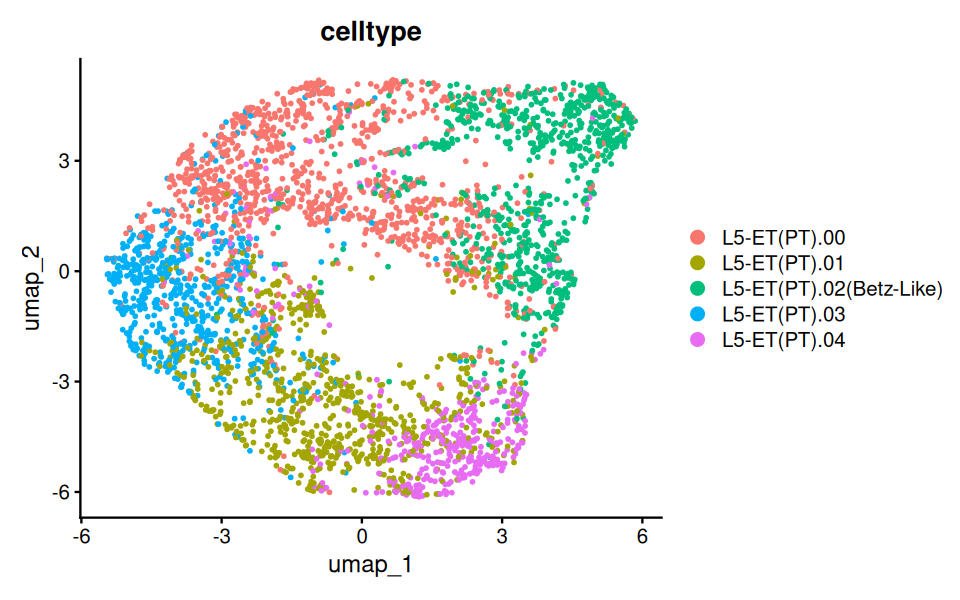

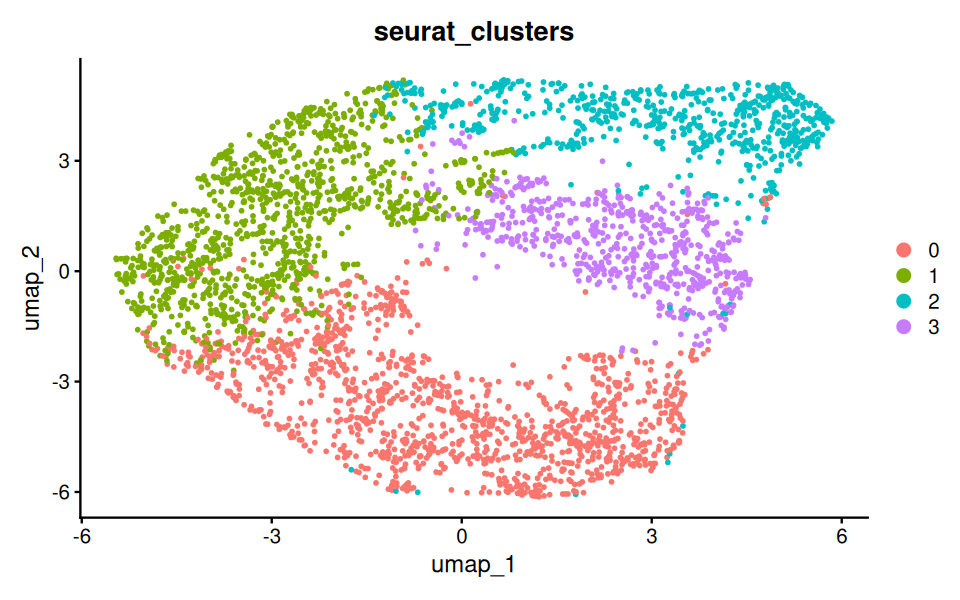

In [17]:
options(repr.plot.width=8, repr.plot.height=5)
DimPlot(M1_data_sub_4,group.by = 'celltype')
DimPlot(M1_data_sub_4,group.by = 'seurat_clusters')

Normalizing layer: counts

Finding variable features for layer counts

Centering and scaling data matrix

Warning message:
“Different features in new layer data than already exists for scale.data”
PC_ 1 
Positive:  OPCML, TMEM132D, ASTN2, SEZ6L, NETO1, CNTN3, SYN3, SLC24A2, TENM4, CPLX1 
	   ADGRL2, NELL1, MAN2A1, CELF4, DNM3, PRKD1, LOC106992602, LOC114674205, MEGF11, KANK4 
	   CACNB2, CCDC60, CDH4, CAMK4, KLHL32, LOC107001044, SYT2, TMEM132C, OBSCN, SRRM4 
Negative:  PTPRK, PDZRN4, CADPS2, SPON1, ARL15, TMTC2, TAFA2, LHFPL3, CBLB, NEGR1 
	   PDE4B, GPC6, SPHKAP, SPOCK1, MGAT4C, C8H8orf34, LINGO2, TMEFF2, CDH10, TMEM117 
	   GRIN3A, LOC114669989, ETV1, GFRA1, NRP1, DAPK1, RORA, KCNH7, PCDH15, LOC106994319 
PC_ 2 
Positive:  LOC106995651, LOC114673457, LOC114677421, LOC106995406, LOC106998467, DPP10, LOC106995407, LOC100425950, AMELY, CTNNA3 
	   EFNA5, LOC106998053, LOC114678473, NLGN4Y, RIT2, UTY, USP9Y, HDAC9, LOC106994024, LOC106995404 
	   TOX, MAP1B, SLIT2, LOC106992911, LOC1146

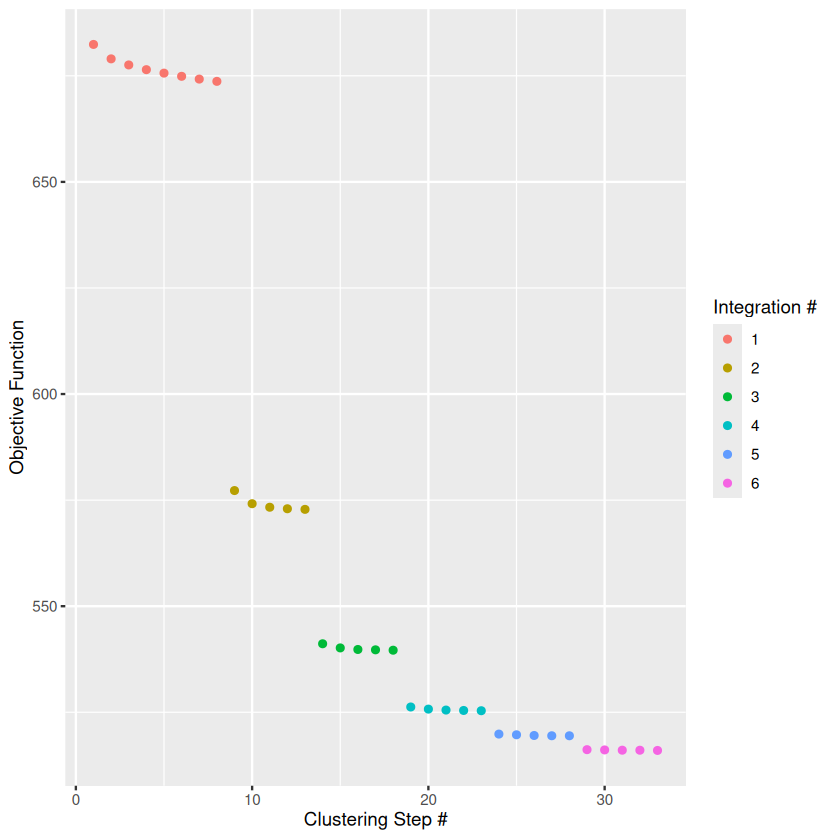

In [7]:
var_Lein_sub = JoinLayers(var_Lein_sub)
var_Lein_sub1 <- var_Lein_sub %>% 
    NormalizeData(normalization.method = "LogNormalize") %>% 
    FindVariableFeatures( nfeatures = 1000) %>% 
    ScaleData() %>% 
    # SCTransform(variable.features.n = 3000) %>% 
    RunPCA(npcs=20) 

var_Lein_sub2 <- var_Lein_sub1 %>% 
    FindNeighbors(dims = 1:5) %>%
    FindClusters(verbose = FALSE, resolution = 0.5, random.seed = 1234) %>%
    RunUMAP(dims = 1:5, seed.use = 1234)

var_Lein_sub3 = RunHarmony(
    var_Lein_sub2, group.by.vars=c("Donor_id"), plot_convergence=T,
    reduction.save = "harmony", dims.use=1:5,
    theta=2)

var_Lein_sub4 <- var_Lein_sub3 %>%
    FindNeighbors(reduction="harmony", dims = 1:5,k.param = 100) %>%
    FindClusters(verbose = FALSE,resolution = 0.4, random.seed = 666) %>%
    RunUMAP(reduction="harmony", dims = 1:5,min.dist = 0.2)



Normalizing layer: counts



Finding variable features for layer counts

Centering and scaling data matrix

Warning message:
“Different features in new layer data than already exists for scale.data”
PC_ 1 
Positive:  ND1, ND3, ND2, NEFL, GAPDH, NEFM, CYTB, GRTP1, MT1X, SLC24A3 
	   ENO2, STMN1, UBXN11, PVALB, TUBA3E, PLP1, PCDH15, SMARCC2, BPHL, COMMD1 
	   CRYBA2, FSIP1, GAL, SERPINA3, APOE, FAIM2, IFI27L2, SLC37A4, FAM166A, MGP 
Negative:  LRP1B, DPP10, KCNIP4, CNTNAP2, ROBO2, FGF14, NRXN3, MACROD2, GRIK2, RBFOX1 
	   ASIC2, FAM19A1, CADM2, SGCZ, ADGRB3, STXBP5L, OPCML, ROBO1, DSCAM, NRG3 
	   FGF12, NLGN1, FRMD4A, CADPS, MAGI2, CTNNA2, MDGA2, NEGR1, CCSER1, KCNMA1 
PC_ 2 
Positive:  TUBB2A, RAB3A, CYTB, ND2, NAP1L5, METTL26, SYP, C1QL3, UROD, ZNF483 
	   SDR39U1, ENO2, ENDOG, FAIM2, KCNJ9, PLPP1, GAPDH, ND1, DNM1, PTGDS 
	   SLC6A7, GDI1, ND3, NSG2, FXYD6, GLUL, MTX1, MAP1A, ELOVL1, APOE 
Negative:  BPHL, FAM166A, PCDH15, DENND5B, SLC24A3, FSIP1, COMMD1, TUBA3E, GRTP1, NME7 
	   SMARCC2, COG5, SHC4, DLG2, TRAF3

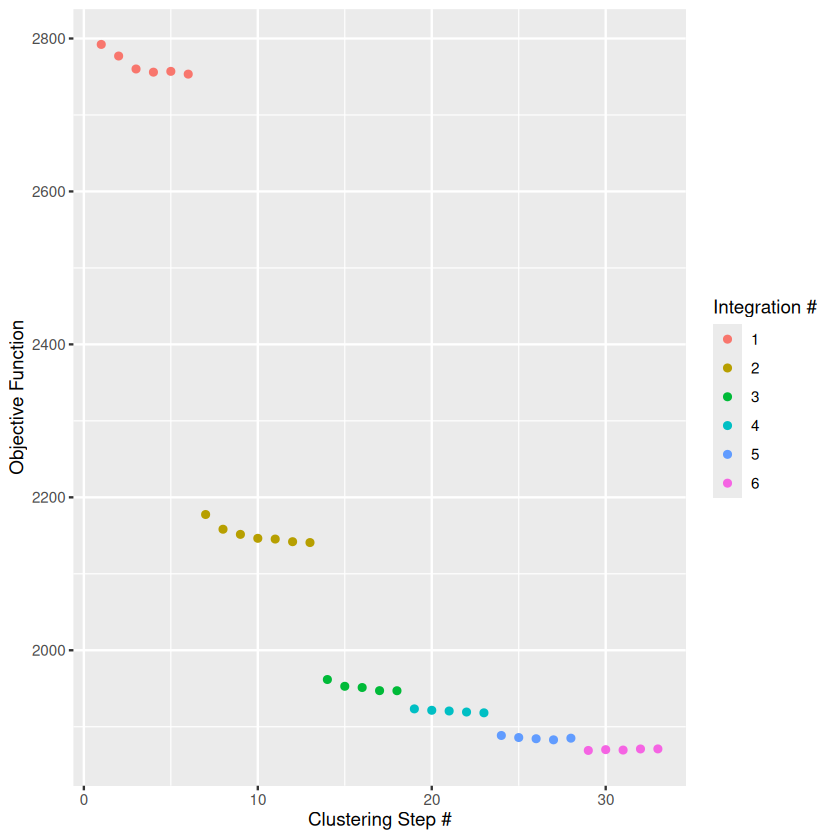

In [8]:
seurat_filt1 <- sub_betz_obj %>% 
    NormalizeData(normalization.method = "LogNormalize") %>% 
    FindVariableFeatures( nfeatures = 3000) %>% 
    ScaleData() %>% 
    # SCTransform(variable.features.n = 3000) %>% 
    RunPCA(npcs=20) 

seurat_filt2 <- seurat_filt1 %>% 
    FindNeighbors(dims = 1:10) %>%
    FindClusters(verbose = FALSE, resolution = 0.5, random.seed = 1234) %>%
    RunUMAP(dims = 1:10, seed.use = 1234)

seurat_filt3 = RunHarmony(
    seurat_filt2, group.by.vars=c("chip","Animal"), plot_convergence=T,
    reduction.save = "harmony", dims.use=1:10,
    theta=c(5,5))

seurat_filt4 <- seurat_filt3 %>%
    FindNeighbors(reduction="harmony", dims = 1:10,k.param = 100) %>%
    FindClusters(verbose = FALSE,resolution = 0.4, random.seed = 666) %>%
    RunUMAP(reduction="harmony", dims = 1:10,min.dist = 0.2)



In [9]:
seurat_filt4$cluster <- paste0(seurat_filt4$source,'_', seurat_filt4$seurat_clusters)

seurat_filt4$cluster %>% unique()

[1] "stRNA_2" "stRNA_1" "stRNA_0"

In [ ]:
# # 将对象放入list
obj_list <- list(
  stRNA = seurat_filt4,
  snRNA = M1_data_sub_4,
  Lein_M1 = var_Lein_sub4
)

features <- VariableFeatures(var_Lein_sub4)[1:1000]
features <- features[features %in% VariableFeatures(M1_data_sub_4)]

# # 找到锚点
anchors <- FindIntegrationAnchors(object.list = obj_list, anchor.features = features, reduction = "cca")

# 整合数据
seurat_cca_integrated <- IntegrateData(
  normalization.method = "LogNormalize",
  anchorset = anchors,
  features.to.integrate = features
)


Scaling features for provided objects



Warning message:
“Different features in new layer data than already exists for scale.data”
Warning message:
“Different features in new layer data than already exists for scale.data”
Warning message:
“Different features in new layer data than already exists for scale.data”
Finding all pairwise anchors

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 6108 anchors

Filtering anchors

	Retained 974 anchors

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 2310 anchors

Filtering anchors

	Retained 1542 anchors

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 2390 anchors

Filtering anchors

	Retained 2052 anchors

Merging dataset 3 into 2

Extracting anchors for merged samples

Finding integration vectors

Finding integration vector weights

Integrating data

Warning message:
“Layer counts isn't present in the assay object; returning NULL”
Merging dataset 1 into 2 3

Extracting anchors for merged samples


In [ ]:
seurat_cca_integrated_1 <- seurat_cca_integrated %>% 
    ScaleData(assay = "integrated",features = features) %>%    
    # 2. Run PCA on the now-scaled "integrated" assay.
    RunPCA(npcs = 50, assay = "integrated",verbose = F) %>% 
    FindNeighbors(dims = 1:7,reduction = "pca",k.param = 40) %>%
    FindClusters(resolution = 3,random.seed = 123)%>%
    # 3. Run UMAP.
    RunUMAP(dims = 1:7 ,assay = "integrated",min.dist = 0.3)


Centering and scaling data matrix

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 5454
Number of edges: 390359

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.5590
Number of communities: 22
Elapsed time: 1 seconds


Warning message:
“UNRELIABLE VALUE: One of the ‘future.apply’ iterations (‘future_lapply-1’) unexpectedly generated random numbers without declaring so. There is a risk that those random numbers are not statistically sound and the overall results might be invalid. To fix this, specify 'future.seed=TRUE'. This ensures that proper, parallel-safe random numbers are produced via a parallel RNG method. To disable this check, use 'future.seed = NULL', or set option 'future.rng.onMisuse' to "ignore".”
12:19:15 UMAP embedding parameters a = 0.9922 b = 1.112

12:19:15 Read 5454 rows and found 7 numeric columns

12:19:15 Using Annoy for neighbor search, n_neighbors = 30

12:19:15 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

12:19:15 Writing NN index file to temp file /tmp/Rtm

In [12]:
sub_downsampled_2 = seurat_cca_integrated_1
sub_downsampled_2$celltype[is.na(sub_downsampled_2$celltype)] <- "stereo_betz"
sub_downsampled_2$celltype %>% unique()

[1] "Betz cell"               "L5-ET(PT).02(Betz-Like)"
[3] "L5-ET(PT).00"            "L5-ET(PT).03"           
[5] "L5-ET(PT).01"            "L5-ET(PT).04"           
[7] "Betz Cell"               "Other L5 Neurons"

In [14]:
# 合并 L5-ET(PT).02(Betz-Like) 和 L5-ET(PT).00 为 celltype_new
sub_downsampled_2$celltype_new <- as.character(sub_downsampled_2$celltype)
sub_downsampled_2$celltype_new[sub_downsampled_2$celltype_new %in% c("L5-ET(PT).02(Betz-Like)", "L5-ET(PT).00")] <- "Betz Like"
sub_downsampled_2$celltype_new <- as.factor(sub_downsampled_2$celltype_new)

In [ ]:
sub_downsampled_2$cluster <- as.character(sub_downsampled_2$celltype_new)

sub_downsampled_2$cluster <- factor(sub_downsampled_2$cluster)

sub_downsampled_2$cluster %>% unique()

[1] Betz cell        Betz Like        L5-ET(PT).03     L5-ET(PT).01    
[5] L5-ET(PT).04     Betz Cell        Other L5 Neurons
7 Levels: Betz cell Betz Cell Betz Like L5-ET(PT).01 ... Other L5 Neurons

In [14]:
# table(sub_downsampled_2$source)
saveRDS(sub_downsampled_2, '/mnt/90-connectome/Personal/CQW//motor_snRNA_new/article/fig5/new_betz/co_betz_snRNA/20251222_co_betz_snRNA_L5ET.rds')


In [2]:
sub_downsampled_2 = readRDS('/mnt/90-connectome/Personal/CQW//motor_snRNA_new/article/fig5/new_betz/co_betz_snRNA/20251222_co_betz_snRNA_L5ET.rds')

In [57]:
sub_downsampled_2$cluster %>% unique()

[1] stRNA_2          stRNA_1          stRNA_0          Betz Like       
[5] L5-ET(PT).03     L5-ET(PT).01     L5-ET(PT).04     Betz Cell       
[9] Other L5 Neurons
9 Levels: Betz Cell Betz Like L5-ET(PT).01 L5-ET(PT).03 ... stRNA_2

In [58]:
table(sub_downsampled_2$cluster)


       Betz Cell        Betz Like     L5-ET(PT).01     L5-ET(PT).03 
             242             1889              798              634 
    L5-ET(PT).04 Other L5 Neurons          stRNA_0          stRNA_1 
             392              241              630              493 
         stRNA_2 
             135 

In [ ]:
Idents(sub_downsampled_2) <- 'celltype_new'
options(repr.plot.width=12, repr.plot.height=4)

# 使用ggsci的pal_nejm配色方案（再换一个配色）
DimPlot(
  sub_downsampled_2, 
  split.by = "source",  
  label = TRUE,
  pt.size = 0.001,
  cols = pal_primer("mark17")(length(unique(sub_downsampled_2$celltype)))
) & labs(title = "V5 Integ")

options(repr.plot.width=6, repr.plot.height=4)
DimPlot(
  sub_downsampled_2,
  group.by = "celltype_new",
  label = TRUE,
  pt.size = 0.001,
  cols = pal_primer("mark17")(length(unique(sub_downsampled_2$celltype)))
) & labs(title = "V5 Integ")


options(repr.plot.width=5, repr.plot.height=4)
DimPlot(
  sub_downsampled_2,
  group.by = "source",
  label = TRUE,
  pt.size = 0.001,
  cols = pal_lancet("lanonc")(length(unique(sub_downsampled_2$source)))
) & labs(title = "V5 Integ")


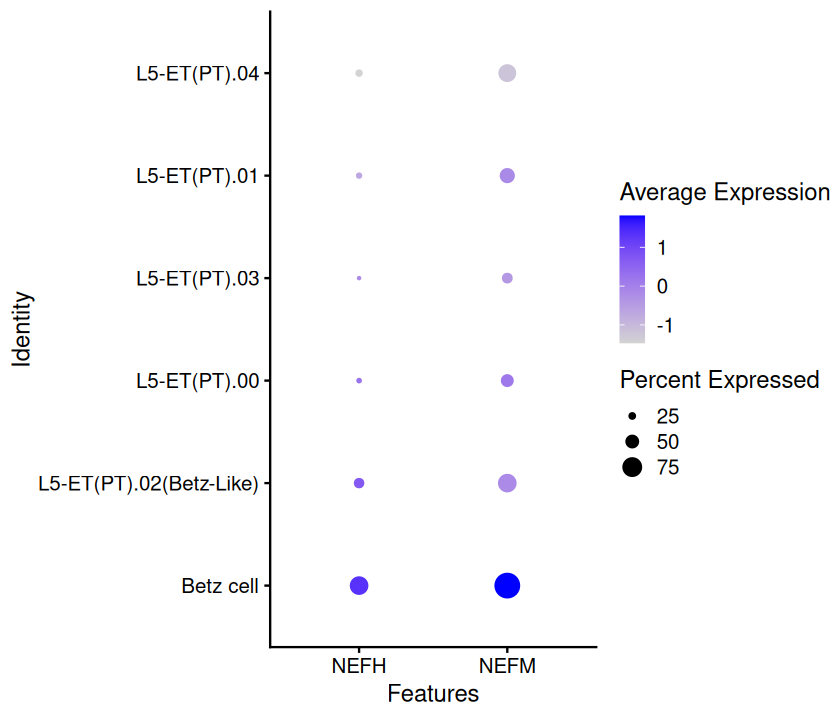

In [ ]:
options(repr.plot.width=7, repr.plot.height=6)
# FeaturePlot(
#   sub_downsampled_2,
#   features = 'NEFH',
#   cols = c("#e0ecf4", "#9ecae1", "#3182bd") # Example of custom blue gradient colors
# )

DotPlot(sub_downsampled_2,features = c('NEFH','NEFM'))

In [18]:
sub_downsampled_2

An object of class Seurat 
48907 features across 5454 samples within 2 assays 
Active assay: integrated (444 features, 444 variable features)
 2 layers present: data, scale.data
 1 other assay present: RNA
 2 dimensional reductions calculated: pca, umap